In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             balanced_accuracy_score, f1_score, roc_auc_score,
                             average_precision_score)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from optuna.samplers import TPESampler
import optuna
from cross_validation_utils import (
    CV_PROTOCOL, split_summary, evaluate_cv, nested_cv,
    print_cv_metrics, summary_row, save_cv_result
)


c:\Users\Mikhael\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('frankfurt_diabetes.csv')
df = df.drop_duplicates().reset_index(drop=True)  # cegah duplicate leakage
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,2,138,62,35,0,33.6,0.127,47,1
1,0,84,82,31,125,38.2,0.233,23,0
2,0,145,0,0,0,44.2,0.630,31,1
3,0,135,68,42,250,42.3,0.365,24,1
4,1,139,62,41,480,40.7,0.536,21,0


In [3]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
739,1,100,62,0,0,64.4,0.152,36,0
740,0,163,40,23,64,40.7,0.322,33,0
741,6,139,84,37,0,50.7,0.320,50,1
742,2,167,44,30,140,52.7,0.452,28,0
743,3,162,0,110,215,48.7,0.520,24,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 744 entries, 0 to 743
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               744 non-null    int64  
 1   Glucose                   744 non-null    int64  
 2   BloodPressure             744 non-null    int64  
 3   SkinThickness             744 non-null    int64  
 4   Insulin                   744 non-null    int64  
 5   BMI                       744 non-null    float64
 6   DiabetesPedigreeFunction  744 non-null    float64
 7   Age                       744 non-null    int64  
 8   Outcome                   744 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 52.4 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,744.0,3.752688,3.335541,0.000,1.000,3.0000,6.0000,17.00
Glucose,744.0,120.892473,31.943115,0.000,99.000,117.0000,140.2500,199.00
BloodPressure,744.0,68.959677,19.317521,0.000,62.000,72.0000,80.0000,122.00
SkinThickness,744.0,20.908602,16.311726,0.000,0.000,23.0000,32.0000,110.00
Insulin,744.0,79.534946,111.745897,0.000,0.000,36.0000,130.0000,744.00
BMI,744.0,32.229704,8.206319,0.000,27.400,32.3000,36.8000,80.60
DiabetesPedigreeFunction,744.0,0.472355,0.326181,0.078,0.244,0.3755,0.6325,2.42
Age,744.0,33.142473,11.751286,21.000,24.000,29.0000,40.2500,81.00
Outcome,744.0,0.340054,0.474046,0.000,0.000,0.0000,1.0000,1.00


In [6]:
df['Outcome'].value_counts()

Outcome
0    491
1    253
Name: count, dtype: int64

In [7]:
df['Outcome'].value_counts(normalize=True)*100

Outcome
0    65.994624
1    34.005376
Name: proportion, dtype: float64

In [8]:
cols_fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Nol pada fitur-fitur ini menandakan nilai klinis yang tidak tercatat.
# Imputasi dilakukan dari data train di dalam pipeline.
df[cols_fix] = df[cols_fix].replace(0, np.nan)
df[cols_fix].isna().sum()

Glucose            5
BloodPressure     34
SkinThickness    215
Insulin          359
BMI               10
dtype: int64

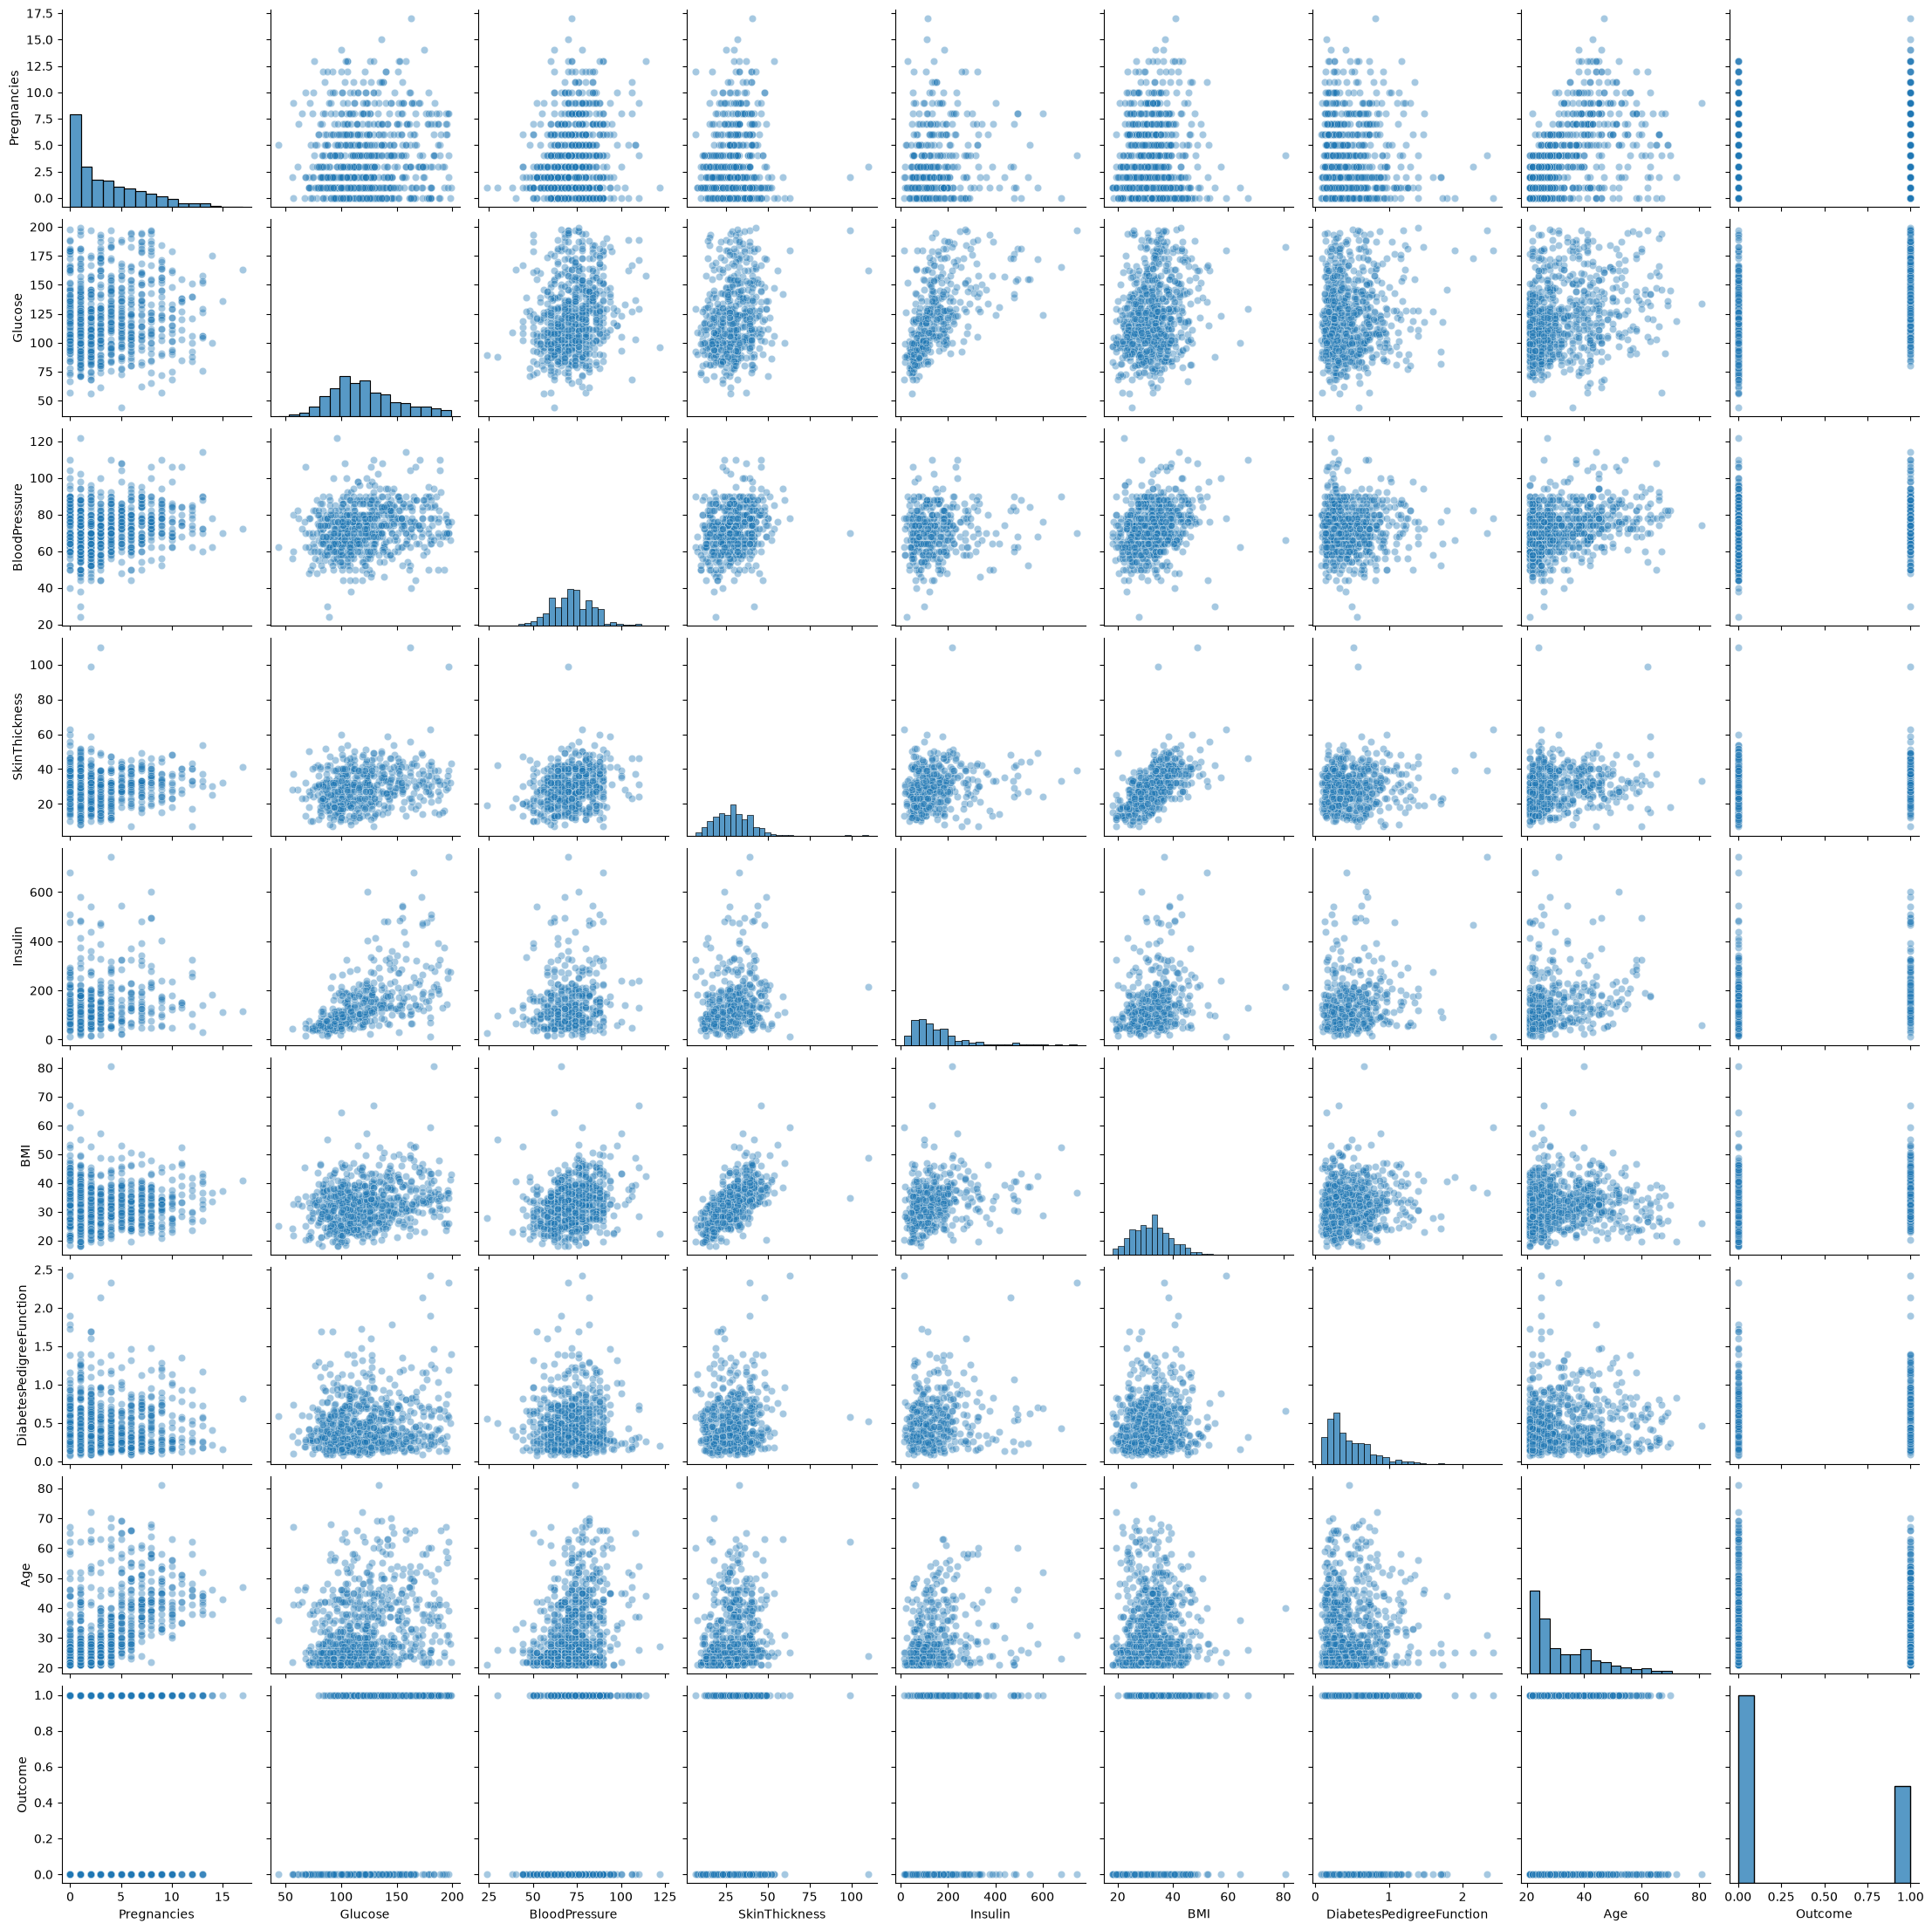

In [9]:
sns.pairplot(df, kind='scatter', plot_kws={'alpha':0.4})

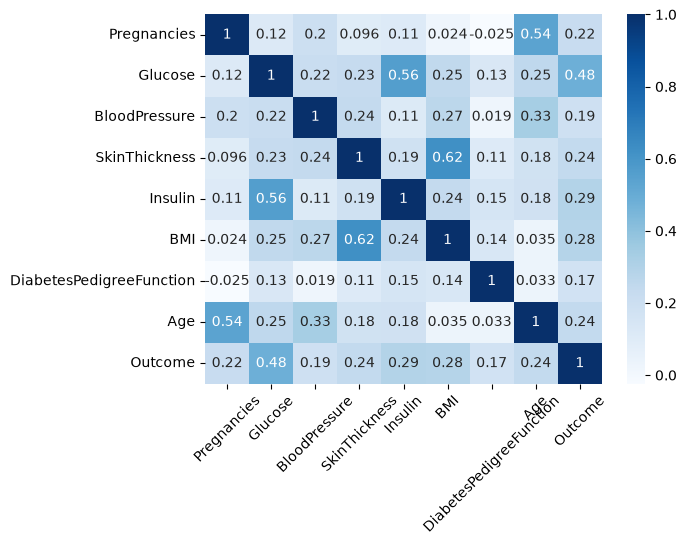

In [10]:
sns.heatmap(df.corr(), annot=True, cmap='Blues')
plt.xticks(rotation=45)
plt.show()

In [11]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

In [12]:
RANDOM_STATE = 42

N_SPLITS = 5

outer_cv = StratifiedKFold(
    n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE
)
groups = None


# Seluruh fold dipakai; setiap baris menjadi validation tepat sekali.
split_summary(X, y, outer_cv, groups)


,Fold,Train,Validation,Positif train,Positif validation
0,1,595,149,202,51
1,2,595,149,202,51
2,3,595,149,202,51
3,4,595,149,203,50
4,5,596,148,203,50


In [13]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(lgbm_params):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(sampling_strategy='minority', random_state=RANDOM_STATE)),
        ('lgbm', LGBMClassifier(
            objective='binary',
            boosting_type='gbdt',
            subsample_freq=1,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1,
            **lgbm_params
        ))
    ])

In [14]:
baseline_params = {
    'num_leaves': 31,
    'max_depth': -1,
    'learning_rate': 0.05,
    'n_estimators': 100,
    'reg_alpha': 0.0,
    'reg_lambda': 0.0
}

In [15]:
baseline_pipeline = make_pipeline(baseline_params)
baseline_cv = evaluate_cv(
    make_pipeline, baseline_params, X, y, outer_cv, groups
)


Outer fold 1/5: train=595, validation=149
Outer fold 2/5: train=595, validation=149
Outer fold 3/5: train=595, validation=149
Outer fold 4/5: train=595, validation=149
Outer fold 5/5: train=596, validation=148


In [16]:
# Prediksi out-of-fold: bukan prediksi pada data latih.
y_pred = baseline_cv['prediction']
y_proba = baseline_cv['probability']


In [17]:
print_cv_metrics(baseline_cv)
print('\nClassification Report (OOF Predictions):')
print(classification_report(y, y_pred, zero_division=0))


Cross-Validation Results (Mean +/- Std):
Accuracy          : 0.7459 +/- 0.0201
Balanced Accuracy : 0.7291 +/- 0.0203
Precision         : 0.6178 +/- 0.0378
Recall            : 0.6761 +/- 0.0627
Specificity       : 0.7820 +/- 0.0473
F1                : 0.6436 +/- 0.0271
ROC-AUC           : 0.8114 +/- 0.0336
PR-AUC            : 0.6715 +/- 0.0460

Classification Report (OOF Predictions):
              precision    recall  f1-score   support

           0       0.82      0.78      0.80       491
           1       0.62      0.68      0.64       253

    accuracy                           0.75       744
   macro avg       0.72      0.73      0.72       744
weighted avg       0.75      0.75      0.75       744



Combined OOF confusion matrix (5 folds): 744 samples.


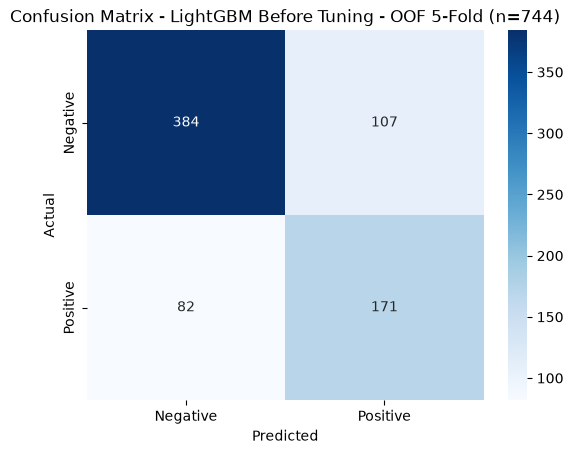

In [18]:
# Confusion matrix gabungan prediksi OOF seluruh outer folds.
# Setiap baris diuji sekali; skor utama tetap mean +/- std antar-fold.
print(f'Combined OOF confusion matrix ({N_SPLITS} folds): {len(y)} samples.')

sns.heatmap(confusion_matrix(y, y_pred), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'])
plt.title(f'Confusion Matrix - LightGBM Before Tuning - OOF {N_SPLITS}-Fold (n={len(y)})')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [19]:
def objective(trial, X_train=X, y_train=y, cv=cv, groups_train=groups):
    max_depth = trial.suggest_int('max_depth', 2, 8)
    trial_params = {
        'max_depth': max_depth,
        'num_leaves': trial.suggest_int('num_leaves', 4, min(2 ** max_depth, 128)),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.30, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 100, 600, step=50),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 60, step=5),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0, step=0.1),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0, step=0.1),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-6, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 20.0, log=True)
    }
    pipeline = make_pipeline(trial_params)
    scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring='f1', n_jobs=1
    )
    return scores.mean()

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 50

# Evaluasi seluruh outer folds; tuning hanya melihat inner training folds.
tuned_cv = nested_cv(
    objective, make_pipeline, X, y, outer_cv, cv,
    n_trials=N_TRIALS, groups=groups, random_state=RANDOM_STATE
)

# Cari parameter model final pada seluruh data setelah evaluasi selesai.
# Model refit ini untuk LIME/deployment, bukan untuk menghitung skor OOF.
study = optuna.create_study(
    direction='maximize', sampler=TPESampler(seed=RANDOM_STATE)
)
study.optimize(objective, n_trials=N_TRIALS)

Outer fold 1/5: train=595, validation=149
Outer fold 2/5: train=595, validation=149
Outer fold 3/5: train=595, validation=149
Outer fold 4/5: train=595, validation=149
Outer fold 5/5: train=596, validation=148


In [20]:
print("Best Params:", study.best_params)
print(f"Best mean CV F1: {study.best_value:.4f}")

# Simpan hasil tuning agar otomatis digunakan notebook perbandingan.
import json
from pathlib import Path

params_path = Path('best_params_fhgdd.json')
tuning_results = (
    json.loads(params_path.read_text(encoding='utf-8'))
    if params_path.exists() else {}
)
# Simpan prediksi dan metrik outer folds untuk notebook komparasi.
cv_result_file = save_cv_result(
    tuned_cv, X, y, groups,
    Path('cv_results/lightgbm_fhgdd.json.gz'), study.best_params
)
outer_scores = summary_row(tuned_cv)
tuning_results['LightGBM'] = {
    'params': study.best_params,
    'cv_f1': float(study.best_value),
    'outer_cv_f1': outer_scores['F1'],
    'outer_cv_f1_std': outer_scores['F1 Std'],
    'evaluation_protocol': CV_PROTOCOL,
    'outer_n_splits': N_SPLITS,
    'inner_n_splits': N_SPLITS,
    'cv_result_file': cv_result_file
}
params_path.write_text(
    json.dumps(tuning_results, indent=2), encoding='utf-8'
)
print(f'Best LightGBM parameters saved to: {params_path.resolve()}')

# Refit pada seluruh data setelah evaluasi; skor tetap dari prediksi OOF.
best_pipeline = make_pipeline(study.best_params)
best_pipeline.fit(X, y)

Best Params: {'max_depth': 4, 'num_leaves': 13, 'learning_rate': 0.026207992983310672, 'n_estimators': 250, 'min_child_samples': 15, 'subsample': 0.6, 'colsample_bytree': 0.9, 'reg_alpha': 5.633996110978046, 'reg_lambda': 1.5808673277813738}
Best mean CV F1: 0.6914
Best LightGBM parameters saved to: D:\TELKOM\PENPRO\Diabetes\Model\temp\best_params_fhgdd.json


,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None


In [21]:
optuna_prediction = tuned_cv['prediction']
optuna_proba = tuned_cv['probability']

print_cv_metrics(tuned_cv)
print('\nClassification Report (OOF Predictions):')
print(classification_report(y, optuna_prediction, zero_division=0))


Cross-Validation Results (Mean +/- Std):
Accuracy          : 0.7567 +/- 0.0309
Balanced Accuracy : 0.7547 +/- 0.0403
Precision         : 0.6177 +/- 0.0352
Recall            : 0.7476 +/- 0.0785
Specificity       : 0.7617 +/- 0.0284
F1                : 0.6754 +/- 0.0469
ROC-AUC           : 0.8261 +/- 0.0361
PR-AUC            : 0.6957 +/- 0.0310

Classification Report (OOF Predictions):
              precision    recall  f1-score   support

           0       0.85      0.76      0.81       491
           1       0.62      0.75      0.68       253

    accuracy                           0.76       744
   macro avg       0.74      0.75      0.74       744
weighted avg       0.77      0.76      0.76       744



In [22]:
baseline_scores = summary_row(baseline_cv)
tuned_scores = summary_row(tuned_cv)

for metric in ['Accuracy', 'F1']:
    print(f"Baseline {metric}: {baseline_scores[metric]:.4f} +/- "
          f"{baseline_scores[f'{metric} Std']:.4f}")
    print(f"Tuned {metric}   : {tuned_scores[metric]:.4f} +/- "
          f"{tuned_scores[f'{metric} Std']:.4f}")


Baseline Accuracy: 0.7459 +/- 0.0201
Tuned Accuracy   : 0.7567 +/- 0.0309
Baseline F1: 0.6436 +/- 0.0271
Tuned F1   : 0.6754 +/- 0.0469


Combined OOF confusion matrix (5 folds): 744 samples.


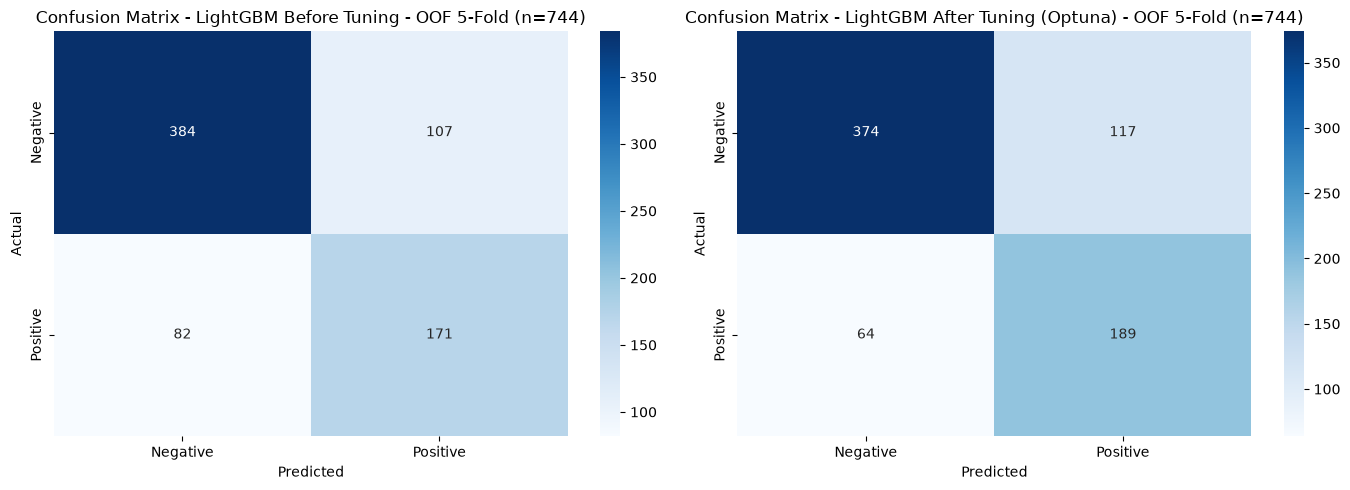

In [23]:
# Confusion matrix gabungan prediksi OOF seluruh outer folds.
# Setiap baris diuji sekali; skor utama tetap mean +/- std antar-fold.
assert np.array_equal(baseline_cv['fold_id'], tuned_cv['fold_id']), \
    'Fold baseline dan tuning harus identik.'
print(f'Combined OOF confusion matrix ({N_SPLITS} folds): {len(y)} samples.')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(confusion_matrix(y, y_pred), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'], ax=ax[0])
ax[0].set_title(f"Confusion Matrix - LightGBM Before Tuning - OOF {N_SPLITS}-Fold (n={len(y)})")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")


sns.heatmap(confusion_matrix(y, optuna_prediction), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'], ax=ax[1])
ax[1].set_title(f"Confusion Matrix - LightGBM After Tuning (Optuna) - OOF {N_SPLITS}-Fold (n={len(y)})")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [24]:
# Variasi antar-fold; bukan bootstrap test set atau confidence interval.
fold_scores = tuned_cv['folds']['Accuracy'].to_numpy()
mean_acc = fold_scores.mean()
std_acc = fold_scores.std(ddof=1)

print(f'Mean Accuracy ({N_SPLITS}-Fold CV): {mean_acc:.4f} +/- {std_acc:.4f}')
tuned_cv['folds'].drop(columns='Best Params').round(4)


Mean Accuracy (5-Fold CV): 0.7567 +/- 0.0309


,Fold,Train Rows,Validation Rows,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,Fit seconds,Inner CV F1
0,1,595,149,0.7114,0.7007,0.5667,0.6667,0.7347,0.6126,0.7675,0.6701,10.2722,0.6734
1,2,595,149,0.7450,0.7262,0.6182,0.6667,0.7857,0.6415,0.8419,0.7392,10.0255,0.6935
2,3,595,149,0.7852,0.7803,0.6610,0.7647,0.7959,0.7091,0.8315,0.6736,10.8900,0.6929
3,4,595,149,0.7852,0.7988,0.6364,0.8400,0.7576,0.7241,0.8646,0.7179,10.4647,0.6728
4,5,596,148,0.7568,0.7673,0.6061,0.8000,0.7347,0.6897,0.8247,0.6778,9.0200,0.6909


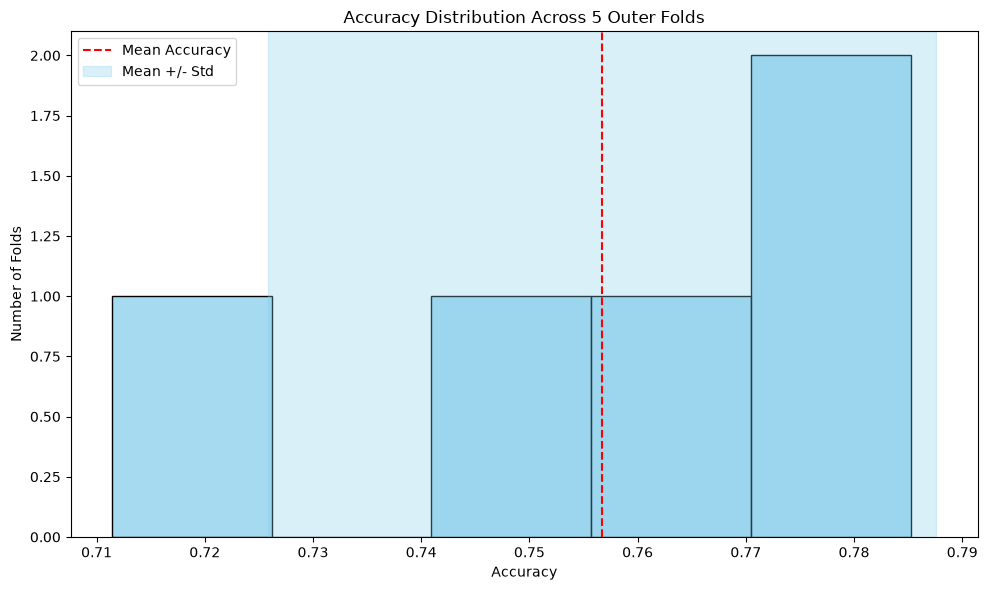

In [25]:
plt.figure(figsize=(10, 6))
sns.histplot(fold_scores, bins=N_SPLITS, color='skyblue')
plt.axvline(mean_acc, color='red', linestyle='--', label='Mean Accuracy')
plt.axvspan(mean_acc - std_acc, mean_acc + std_acc,
            color='skyblue', alpha=0.3, label='Mean +/- Std')
plt.title(f'Accuracy Distribution Across {N_SPLITS} Outer Folds')
plt.xlabel('Accuracy')
plt.ylabel('Number of Folds')
plt.legend()
plt.tight_layout()
plt.show()


In [26]:
from lime.lime_tabular import LimeTabularExplainer
import random

In [27]:
# LIME menggunakan model final yang sudah direfit pada seluruh data.
X_imputed = pd.DataFrame(
    best_pipeline.named_steps['imputer'].transform(X),
    columns=X.columns, index=X.index
)

explainer = LimeTabularExplainer(
    training_data=X_imputed.values,     
    feature_names=X.columns.tolist(),   
    class_names=['Negative', 'Positive'], 
    mode='classification',                    
    random_state=42
)

In [28]:
rng_lime = np.random.default_rng(RANDOM_STATE)
sample_index = int(rng_lime.integers(0, len(X)))
sample_data = X.iloc[sample_index]
sample_data_imputed = best_pipeline.named_steps['imputer'].transform(
    sample_data.to_frame().T
)[0]

def lime_predict(data):
    data_df = pd.DataFrame(data, columns=X.columns)
    return best_pipeline.predict_proba(data_df)

exp = explainer.explain_instance(
    data_row=sample_data_imputed,
    predict_fn=lime_predict,
    num_features=5
)

In [29]:
from IPython.display import HTML, display

html_output = exp.as_html(show_table=True, show_all=False)
actual_label = 'Positive' if y.iloc[sample_index] == 1 else 'Negative'
print(f'Actual value for sample index {sample_index}: {actual_label}')
display(HTML(html_output))


Actual value for sample index 66: Positive


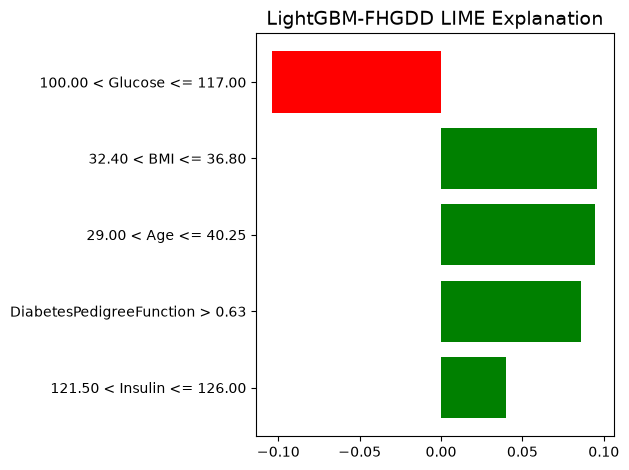

LIME image saved to: D:\TELKOM\PENPRO\Diabetes\Model\temp\lime_lightgbm_fhgdd.png


In [30]:
from pathlib import Path

output_path = Path('lime_lightgbm_fhgdd.png')

label = exp.available_labels()[0]
fig = exp.as_pyplot_figure(label=label)
fig.axes[0].set_title('LightGBM-FHGDD LIME Explanation', fontsize=14)

fig.tight_layout()
fig.savefig(
    output_path,
    format='png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
print(f'LIME image saved to: {output_path.resolve()}')
